# Case Study: Sales Data Quality Audit

A compact data-quality workflow: identify issues, document rules, clean, summarize, and visualize.

> 🧭 This notebook focuses on practical data work. Examples are intentionally compact and do not cover machine learning.

## Case study questions
- Which records need review before analysis?
- How should missing prices, duplicate transaction IDs, and inconsistent category labels be handled?
- What can a cleaned summary say, and what still needs a business decision?

The data are synthetic and designed to illustrate common problems. This is a short data-quality audit, not a predictive modeling project.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

raw = pd.DataFrame({
    "transaction_id": [1001, 1002, 1003, 1003, 1004, 1005, 1006, 1007],
    "date": ["2025-03-01", "2025-03-02", "2025-03-02", "2025-03-02", "2025-03-04", "bad-date", "2025-03-06", "2025-03-07"],
    "category": ["Food", " food ", "Books", "Books", "Home", "FOOD", None, "Books"],
    "units": [2, 1, 3, 3, 1, 4, 2, 1],
    "unit_price": [12.0, None, 8.5, 8.5, 45.0, 11.0, -2.0, 10.0],
})
display(raw)
print("Shape:", raw.shape)
print("Missing:\n", raw.isna().sum())
print("Exact duplicates:", raw.duplicated().sum())

Shape: (8, 5)
Missing:
 transaction_id    0
date              0
category          1
units             0
unit_price        1
dtype: int64
Exact duplicates: 1


,transaction_id,date,category,units,unit_price
0,1001,2025-03-01,Food,2,12.0
1,1002,2025-03-02,food,1,NaN
2,1003,2025-03-02,Books,3,8.5
3,1003,2025-03-02,Books,3,8.5
4,1004,2025-03-04,Home,1,45.0
5,1005,bad-date,FOOD,4,11.0
6,1006,2025-03-06,None,2,-2.0
7,1007,2025-03-07,Books,1,10.0


## Document and apply cleaning rules
This example uses explicit rules: normalize category labels, parse dates with invalid values set to `NaT`, flag duplicate IDs, and flag non-positive prices. It does not silently delete flagged records.

In [2]:
audit = raw.copy()
audit["category"] = audit["category"].astype("string").str.strip().str.title()
audit["date"] = pd.to_datetime(audit["date"], errors="coerce")
audit["duplicate_id_flag"] = audit.duplicated(subset=["transaction_id"], keep="first")
audit["invalid_date_flag"] = audit["date"].isna()
audit["invalid_price_flag"] = audit["unit_price"].le(0) | audit["unit_price"].isna()
audit["missing_category_flag"] = audit["category"].isna() | audit["category"].eq("<NA>")
display(audit)

,transaction_id,date,category,units,unit_price,duplicate_id_flag,invalid_date_flag,invalid_price_flag,missing_category_flag
0,1001,2025-03-01,Food,2,12.0,False,False,False,False
1,1002,2025-03-02,Food,1,NaN,False,False,True,False
2,1003,2025-03-02,Books,3,8.5,False,False,False,False
3,1003,2025-03-02,Books,3,8.5,True,False,False,False
4,1004,2025-03-04,Home,1,45.0,False,False,False,False
5,1005,NaT,Food,4,11.0,False,True,False,False
6,1006,2025-03-06,<NA>,2,-2.0,False,False,True,True
7,1007,2025-03-07,Books,1,10.0,False,False,False,False


## Clean only after choosing rules
For this teaching example, retain the first transaction ID, exclude invalid dates, and treat non-positive prices as invalid. Missing price values are imputed with the median valid price as an explicit demonstration choice; production choices should follow business context.

In [3]:
clean = audit.loc[~audit["duplicate_id_flag"] & ~audit["invalid_date_flag"]].copy()
valid_prices = clean.loc[clean["unit_price"] > 0, "unit_price"]
median_price = valid_prices.median()
clean["price_was_imputed"] = clean["unit_price"].isna() | clean["unit_price"].le(0)
clean.loc[clean["unit_price"].le(0) | clean["unit_price"].isna(), "unit_price"] = median_price
clean["category"] = clean["category"].fillna("Unknown")
clean["revenue"] = clean["units"] * clean["unit_price"]
display(clean)
print("Rows before:", len(raw), "Rows after rule-based filtering:", len(clean))

Rows before: 8 Rows after rule-based filtering: 6


,transaction_id,date,category,units,unit_price,duplicate_id_flag,invalid_date_flag,invalid_price_flag,missing_category_flag,price_was_imputed,revenue
0,1001,2025-03-01,Food,2,12.0,False,False,False,False,False,24.0
1,1002,2025-03-02,Food,1,11.0,False,False,True,False,True,11.0
2,1003,2025-03-02,Books,3,8.5,False,False,False,False,False,25.5
4,1004,2025-03-04,Home,1,45.0,False,False,False,False,False,45.0
6,1006,2025-03-06,Unknown,2,11.0,False,False,True,True,True,22.0
7,1007,2025-03-07,Books,1,10.0,False,False,False,False,False,10.0


,category,transactions,units,revenue
2,Home,1,1,45.0
0,Books,2,4,35.5
1,Food,2,3,35.0
3,Unknown,1,2,22.0


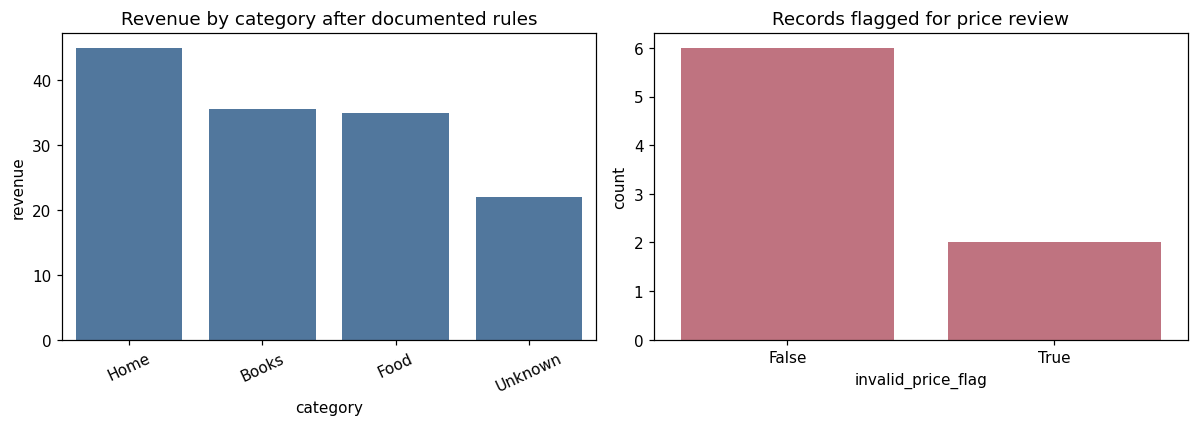

In [4]:
summary = clean.groupby("category", as_index=False, observed=False).agg(
    transactions=("transaction_id", "nunique"), units=("units", "sum"), revenue=("revenue", "sum")
).sort_values("revenue", ascending=False)
display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=summary, x="category", y="revenue", color="#4477AA", ax=axes[0])
axes[0].set_title("Revenue by category after documented rules")
axes[0].tick_params(axis="x", rotation=25)
sns.countplot(data=audit, x="invalid_price_flag", color="#CC6677", ax=axes[1])
axes[1].set_title("Records flagged for price review")
plt.tight_layout()
plt.show()

## Short audit report
A good audit communicates: the rule applied, number of rows affected, how values were imputed or excluded, remaining caveats, and the decision owner. Cleaning is a documented decision process, not just a sequence of convenience functions.

In [5]:
audit_summary = pd.DataFrame({
    "check": ["input rows", "duplicate transaction IDs after first occurrence", "invalid dates", "missing categories", "invalid or missing prices"],
    "count": [len(raw), int(audit["duplicate_id_flag"].sum()), int(audit["invalid_date_flag"].sum()), int(audit["missing_category_flag"].sum()), int(audit["invalid_price_flag"].sum())],
})
display(audit_summary)
print("Report note: median price imputation is illustrative and should be validated with the data owner.")

Report note: median price imputation is illustrative and should be validated with the data owner.


,check,count
0,input rows,8
1,duplicate transaction IDs after first occurrence,1
2,invalid dates,1
3,missing categories,1
4,invalid or missing prices,2


## Practice
Add a new quality flag for zero or negative unit quantities. Report how many rows are affected before deciding whether to remove them.

In [6]:
audit["invalid_units_flag"] = audit["units"].le(0)
print("Invalid unit quantity count:", int(audit["invalid_units_flag"].sum()))
display(audit.loc[audit["invalid_units_flag"]])

Invalid unit quantity count: 0


,transaction_id,date,category,units,unit_price,duplicate_id_flag,invalid_date_flag,invalid_price_flag,missing_category_flag,invalid_units_flag
